# EE2211 — Master quiz notebook
### Based on Tutorials 3–6: question type → theory → editable Python

**How to use during practice or a quiz**
1. Select the same Python environment you use for the tutorials. Run the **four setup code cells** below once after starting or restarting the kernel.
2. Jump to the matching question using the index. Each numbered question works independently after setup; run its code cells in order.
3. Replace values under **`EDIT INPUTS`**, then run the cell with **Shift+Enter**. Saved outputs illustrate the supplied examples; rerun after every edit.
4. For a linear system, enter the coefficient/design matrix exactly as given. For `PolyReg` / `PolyCls`, enter **raw features** and let `include_bias=True` add the intercept.

**Scope.** Sources: [Tut3](Code/Tut3.ipynb), [Tut4](Code/Tut4.ipynb), [Tut5](Code/Tut5.ipynb), [Tut6](Code/Tut6.ipynb). All imported libraries and numerical functions already appear in these files. The setup adapts their `checkLR`, `analyze_linear_system`, `PolyReg`, and `PolyCls` reference functions. Comments identify corrections: rank checks, consistent target shapes, use of `transform` for prediction, and decoding the actual class labels. No new third-party library or numerical solver is introduced.

**Conventions:** $m$ = number of samples/equations, $d$ = number of columns in the design matrix, $k$ = number of outputs/classes. One sample/equation per row. Use `@` for matrix multiplication in Python; `*` multiplies elementwise.


## Question index

| Question type | Source |
| :--- | :--- |
| [1. Shapes, transpose, and entering matrices](#q01) | Tut4 shapes; Tut6 reshape |
| [2. Discrete sample space and a probability distribution](#q02) | Tut3 Q4(a) |
| [3. Probability of an event involving three dice](#q03) | Tut3 Q4(b) |
| [4. Normal distribution probabilities and PDF/CDF](#q04) | Tut3 Q5 |
| [5. Rank, determinant, and left/right/two-sided inverses](#q05) | Tut3 Q10; Tut4 Q1–8, checkLR; Tut6 Q7 |
| [6. Classify any linear system and select its solution](#q06) | Tut4 reference system analysis |
| [7. Square system: unique exact solution](#q07) | Tut4 Q1; Tut5 Q2 |
| [8. Tall system: least squares and residuals](#q08) | Tut4 Q3 |
| [9. Wide system: minimum-norm exact solution](#q09) | Tut4 Q4, Q6 |
| [10. Null space and a family of solutions](#q10) | Tut4 Q6 SVD + reference analysis |
| [11. Plot two-variable equations](#q11) | Tut4 Q1–3 |
| [12. Plot two planes and their solution line (optional)](#q12) | Tut4 Q6 |
| [13. Linear regression with/without an intercept](#q13) | Tut5 Q1–3 |
| [14. Multiple features and multiple outputs](#q14) | Tut5 Q2, Q9 |
| [15. Construct polynomial features and inspect their order](#q15) | Tut6 Q2–3 |
| [16. Polynomial regression and new predictions](#q16) | Tut5 PolyReg; Tut6 Q2 |
| [17. Wide polynomial model: dual solution](#q17) | Tut6 Q3 |
| [18. Ridge regression: primal and dual formulas](#q18) | Tut5 PolyReg; Tut6 Q3 |
| [19. Train/test split and regression MSE](#q19) | Tut5 Q6, PolyReg |
| [20. Binary classification using the sign of a score](#q20) | Tut6 Q4 |
| [21. Multiclass classification with one-hot labels](#q21) | Tut6 Q5 |
| [22. Polynomial/ridge multiclass classification](#q22) | Tut6 Q5, PolyCls |
| [23. Classification split, accuracy, and degree comparison](#q23) | Tut6 Q6 |
| [24. Load your own CSV (optional)](#q24) | Tut5 Q5–6 |
| [25. Duplicate observations (optional; tutorial marks this out of scope)](#q25) | Tut5 Q4 |

**Fast method choice:** square + full rank → inverse; tall + full column rank → left inverse; wide + full row rank → right inverse. For a rank-deficient design use the tutorial's pseudoinverse. For ridge with $\lambda>0$, use primal or dual ridge, choosing the smaller matrix to invert.


## Setup 1 of 4 — imports

Run all four setup cells once. Imports below are copied from the tutorial set. Pandas and the bundled Iris data are imported only inside the optional/data questions that use them.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, accuracy_score
from collections import defaultdict
from pprint import pprint

print("Tutorial imports ready. Run setup 2, 3, and 4 next.")


Tutorial imports ready. Run setup 2, 3, and 4 next.


## Setup 2 of 4 — tutorial matrix/system helpers

`checkLR(X)` prints which inverse exists and returns it, or returns `None`. `analyze_linear_system(X, y)` retains the tutorial's **two-dictionary return format**: pseudoinverse analysis and the applicable Tut4 inverse method.

**Corrections to Tut4:** targets are kept as columns to prevent accidental broadcasting. The absolute singular-value cutoff `tol` is also converted to the relative cutoff required by `pinv`, so the rank and solution use the same threshold. Assertions are Python syntax added to catch input mistakes early. Rank decisions are numerical: change `tol` only if the scale/precision of the question warrants it.


In [2]:
# Adapted from Tut4: checkLR and analyze_linear_system.
# Only numerical functions already used in Tut3–Tut6 are called.
def checkLR(X, tol=None):
    X = np.array(X, dtype=float)
    assert len(X.shape) == 2, "Enter a 2-D matrix: [[row1], [row2], ...]."
    m, d = X.shape
    rank = np.linalg.matrix_rank(X, tol=tol)
    print("Shape:", X.shape, "  Rank:", rank)
    inverse = None
    if m == d:
        print("Determinant:", np.linalg.det(X))
        if rank == d:
            inverse = np.linalg.inv(X)
            print("Two-sided inverse exists:\n", inverse)
            print("X @ inverse:\n", X @ inverse)
            print("inverse @ X:\n", inverse @ X)
        else:
            print("Singular square matrix: no two-sided, left, or right inverse.")
    elif rank == d:
        inverse = np.linalg.inv(X.T @ X) @ X.T
        print("Left inverse exists (full column rank):\n", inverse)
        print("Left inverse @ X (identity):\n", inverse @ X)
    elif rank == m:
        inverse = X.T @ np.linalg.inv(X @ X.T)
        print("Right inverse exists (full row rank):\n", inverse)
        print("X @ right inverse (identity):\n", X @ inverse)
    else:
        print("Neither a left inverse nor a right inverse exists.")
    return inverse


def analyze_linear_system(X, y, tol=1e-10):
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=float)
    assert len(X.shape) == 2, "X must be a 2-D matrix."
    if len(y.shape) == 1:
        y = y.reshape(-1, 1)
    assert len(y.shape) == 2 and y.shape[1] == 1, "Use one target column here."
    m, d = X.shape
    assert y.shape[0] == m, "X and y must have the same number of rows."
    assert tol > 0, "tol must be positive."

    rank_X = np.linalg.matrix_rank(X, tol=tol)
    rank_aug = np.linalg.matrix_rank(np.hstack([X, y]), tol=tol)
    nullity = d - rank_X
    singular_values = np.linalg.svd(X, compute_uv=False)
    # Correction: matrix_rank uses an absolute cutoff; pinv uses a relative one.
    rcond = tol / singular_values[0] if singular_values[0] > 0 else tol
    w_star = np.linalg.pinv(X, rcond=rcond) @ y
    consistent = (rank_X == rank_aug)

    if consistent and nullity == 0:
        solution_type = "Unique exact solution"
    elif consistent:
        solution_type = "Infinitely many exact solutions (minimum-norm returned)"
    elif nullity == 0:
        solution_type = "No exact solution; unique least-squares solution"
    else:
        solution_type = "No exact solution; infinitely many least-squares solutions (minimum-norm returned)"

    if m == d and rank_X == d:
        method = "Two-sided inverse"
        w_tut4 = np.linalg.inv(X) @ y
    elif rank_X == d:
        method = "Left inverse / least squares"
        w_tut4 = np.linalg.inv(X.T @ X) @ X.T @ y
    elif rank_X == m:
        method = "Right inverse / minimum norm"
        w_tut4 = X.T @ np.linalg.inv(X @ X.T) @ y
    else:
        method = "Rank deficient: Tut4 pseudoinverse fallback"
        w_tut4 = w_star

    result_pinv = {
        "consistent": consistent,
        "solution_type": solution_type,
        "rank_X": rank_X,
        "rank_augmented": rank_aug,
        "nullity": nullity,
        "solution": w_star,
        "residual_norm": np.linalg.norm(X @ w_star - y),
    }
    result_tut4 = {
        "inverse_type_tut4": method,
        "solution_tut4": w_tut4,
        "residual_norm_tut4": np.linalg.norm(X @ w_tut4 - y),
    }
    return result_pinv, result_tut4

print("Matrix/system helpers ready.")


Matrix/system helpers ready.


## Setup 3 of 4 — tutorial regression helper

`w, train_mse, test_mse = PolyReg(X_train, y_train, X_test, y_test, n=1, lmd=0.0, include_bias=True)`

Inputs are **raw** features, shape $(m,p)$; targets may be $(m,)$, $(m,1)$ or $(m,k)$. `n=1` is linear; `n>1` is polynomial; `lmd>0` is ridge. `include_bias=True` inserts the constant feature. Set it to `False` if a question forbids an intercept or your input already is a supplied design matrix (use `n=1` in that case). The return format matches Tut5; test MSE is `None` when test labels are absent.

**Adaptation:** the tutorial selects an inverse by shape; this version checks rank too and uses the `pinv` already present in Tut4 if no valid inverse exists. It prints the chosen method. The explicit inverse formulas match the course; for ill-conditioned data, normal equations can lose accuracy even when rank appears full.


In [3]:
# Adapted from Tut5 PolyReg; same three returned values.
def PolyReg(X_train, y_train, X_test=None, y_test=None,
            n=1, lmd=0.0, include_bias=True):
    X_train = np.array(X_train, dtype=float)
    y_train = np.array(y_train, dtype=float)
    assert len(X_train.shape) == 2, "Use [[x1], [x2], ...] for one feature."
    if len(y_train.shape) == 1:
        y_train = y_train.reshape(-1, 1)
    assert len(y_train.shape) == 2, "Targets must be a vector or 2-D matrix."
    assert X_train.shape[0] == y_train.shape[0], "Training row counts differ."
    assert n >= 1, "Degree n must be at least 1; enter an integer."
    assert lmd >= 0, "Use lmd = 0 (ordinary) or lmd > 0 (ridge)."

    poly = PolynomialFeatures(n, include_bias=include_bias)
    P = poly.fit_transform(X_train)
    m, d = P.shape
    rank = np.linalg.matrix_rank(P)

    if lmd > 0 and m >= d:
        w = np.linalg.inv(P.T @ P + lmd * np.identity(d)) @ P.T @ y_train
        method = "Primal ridge"
    elif lmd > 0:
        w = P.T @ np.linalg.inv(P @ P.T + lmd * np.identity(m)) @ y_train
        method = "Dual ridge"
    elif m == d and rank == d:
        w = np.linalg.inv(P) @ y_train
        method = "Two-sided inverse"
    elif rank == d:
        w = np.linalg.inv(P.T @ P) @ P.T @ y_train
        method = "Left inverse / least squares"
    elif rank == m:
        w = P.T @ np.linalg.inv(P @ P.T) @ y_train
        method = "Right inverse / minimum norm"
    else:
        # pinv is allowed: it appears in Tut4's reference analysis function.
        w = np.linalg.pinv(P) @ y_train
        method = "Rank deficient: pseudoinverse (minimum-norm least squares)"

    train_mse = mean_squared_error(y_train, P @ w)
    test_mse = None
    if X_test is not None:
        X_test = np.array(X_test, dtype=float)
        assert len(X_test.shape) == 2, "X_test must be 2-D."
        assert X_test.shape[1] == X_train.shape[1], "Train/test feature counts differ."
        # Correction to some Tut6 cells: reuse the training feature mapping.
        P_test = poly.transform(X_test)
        if y_test is not None:
            y_test = np.array(y_test, dtype=float)
            if len(y_test.shape) == 1:
                y_test = y_test.reshape(-1, 1)
            assert y_test.shape == (X_test.shape[0], y_train.shape[1]), "Test target shape differs."
            test_mse = mean_squared_error(y_test, P_test @ w)
    else:
        assert y_test is None, "Provide X_test as well as y_test."
    print("Design shape:", P.shape, " Rank:", rank, " Method:", method)
    return w, train_mse, test_mse

print("PolyReg ready.")


PolyReg ready.


## Setup 4 of 4 — tutorial categorical classification helper

`W, train_accuracy, test_accuracy = PolyCls(X_train, y_train, X_test, y_test, n=1, lmd=0.0)`

Supply **one class label per sample**, not a one-hot matrix. This helper one-hot encodes labels, reuses the regression formulas, then selects the largest class score. Its three returned values match Tut6. `include_bias` works as in `PolyReg`.

**Correction to Tut6:** `argmax` returns column **indices**, not necessarily the class labels. Decoding with the encoder's `categories_` supports labels such as `1, 2, 3`, `10, 20, 30`, or strings. The tutorial's plain `argmax` works only for labels `0,...,K-1`; `argmax + 1` works only for `1,...,K`. A tie uses the first category. These regression scores are not probabilities.


In [4]:
# Adapted from Tut6 PolyCls; same three returned values.
def PolyCls(X_train, y_train, X_test=None, y_test=None,
            n=1, lmd=0.0, include_bias=True):
    X_train = np.array(X_train, dtype=float)
    y_train = np.array(y_train)
    assert len(X_train.shape) == 2, "Training features must be 2-D."
    assert len(y_train.shape) == 1 or (len(y_train.shape) == 2 and y_train.shape[1] == 1), "One class label per row is required."
    y_train = y_train.reshape(-1, 1)
    assert X_train.shape[0] == y_train.shape[0], "Training row counts differ."

    ohe = OneHotEncoder(sparse_output=False)  # Same constructor as Tut6.
    Y = ohe.fit_transform(y_train)
    # Reuse the Tut5 regression workflow for the one-hot target matrix.
    W, _, _ = PolyReg(X_train, Y, n=n, lmd=lmd, include_bias=include_bias)
    poly = PolynomialFeatures(n, include_bias=include_bias)
    P_train = poly.fit_transform(X_train)
    classes = ohe.categories_[0]  # Correction: preserve actual label values/order.
    train_labels = classes[np.argmax(P_train @ W, axis=1)]
    train_accuracy = accuracy_score(y_train.ravel(), train_labels)

    test_accuracy = None
    if X_test is not None:
        X_test = np.array(X_test, dtype=float)
        P_test = poly.transform(X_test)
        test_labels = classes[np.argmax(P_test @ W, axis=1)]
        if y_test is not None:
            y_test = np.array(y_test)
            assert len(y_test.shape) == 1 or (len(y_test.shape) == 2 and y_test.shape[1] == 1), "One test label per row is required."
            assert len(y_test) == len(X_test), "Test row counts differ."
            test_accuracy = accuracy_score(y_test.ravel(), test_labels)
    else:
        assert y_test is None, "Provide X_test as well as y_test."
    return W, train_accuracy, test_accuracy

print("All setup complete. Jump to any numbered question below.")


All setup complete. Jump to any numbered question below.


<a id="q01"></a>
## 1. Question type: enter a matrix/vector and fix its shape
**Source:** Tut4 shapes; Tut6 reshape.

**Theory.** In $Xw=y$, an $m\times d$ matrix multiplies a $d\times1$ vector to produce an $m\times1$ target. Transpose swaps rows and columns; reshape reorganizes the same elements. A one-dimensional array has shape `(m,)` and is not a column matrix. Subtracting `(m,)` from `(m,1)` can silently create an $m\times m$ array through broadcasting.

**Your input:** `[[a, b], [c, d]]` is a two-row matrix. One feature for three samples: `[[x1], [x2], [x3]]`. One sample with three features: `[[x1, x2, x3]]`. Prefer targets `[[y1], [y2], ...]`. Do not transpose a problem unless it is needed to put it into $Xw=y$.


In [5]:
# EDIT INPUTS
X = np.array([[1, 2],
              [3, 4],
              [5, 6]], dtype=float)
y_values = np.array([7, 8, 9], dtype=float)

y = y_values.reshape(-1, 1)
print("X shape:", X.shape, " y shape:", y.shape)
print("X transpose:\n", X.T)
print("y as a column:\n", y)
print("y as a row:\n", y_values.reshape(1, -1))
print("X.T @ y shape:", (X.T @ y).shape)


X shape: (3, 2)  y shape: (3, 1)
X transpose:
 [[1. 3. 5.]
 [2. 4. 6.]]
y as a column:
 [[7.]
 [8.]
 [9.]]
y as a row:
 [[7. 8. 9.]]
X.T @ y shape: (2, 1)


<a id="q02"></a>
## 2. Question type: enumerate equally likely outcomes and find a PMF
**Source:** Tut3 Q4(a).

**Theory.** For equally likely outcomes, $P(A)=|A|/|\Omega|$. Two independent fair six-sided dice have $6^2=36$ **ordered** outcomes; `(1, 6)` and `(6, 1)` are different. For $S=D_1+D_2$, group outcomes by their sum to obtain $P(S=s)$. The denominator is the number of outcomes, not the number of distinct sums. Unequal outcome probabilities require weighting, so simple counting would not apply.

**Your input:** change `sides` and `target_sum`. To study another discrete random variable, replace `i + j` in the dictionary with its formula. To change the event, edit the condition in `event_outcomes`.


In [6]:
# EDIT INPUTS — fair, independent dice
sides = 6
target_sum = 7

outcomes = {(i, j): i + j
            for i in range(1, sides + 1)
            for j in range(1, sides + 1)}
grouped = defaultdict(list)
for outcome, value in outcomes.items():
    grouped[value].append(outcome)
pmf = {value: len(group) / len(outcomes) for value, group in grouped.items()}
event_outcomes = [outcome for outcome, value in outcomes.items() if value == target_sum]

print("Total ordered outcomes:", len(outcomes))
print("Favourable outcomes:", event_outcomes)
print("Probability:", len(event_outcomes) / len(outcomes))
print("PMF (sum -> probability):")
pprint(pmf)
pmf_total = 0
for probability in pmf.values():
    pmf_total += probability
print("PMF total:", pmf_total)
# Optional: pprint(grouped) to inspect which outcomes produce each value.


Total ordered outcomes: 36
Favourable outcomes: [(1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)]
Probability: 0.16666666666666666
PMF (sum -> probability):
{2: 0.027777777777777776,
 3: 0.05555555555555555,
 4: 0.08333333333333333,
 5: 0.1111111111111111,
 6: 0.1388888888888889,
 7: 0.16666666666666666,
 8: 0.1388888888888889,
 9: 0.1111111111111111,
 10: 0.08333333333333333,
 11: 0.05555555555555555,
 12: 0.027777777777777776}
PMF total: 1.0000000000000002


<a id="q03"></a>
## 3. Question type: count outcomes satisfying an inequality
**Source:** Tut3 Q4(b).

**Theory.** Enumerate the $s^3$ ordered outcomes and evaluate the event as `True` or `False`. The tutorial asks for $P(D_1D_2D_3/2>D_1+D_2+D_3)$. Strict `>` and non-strict `>=` describe different events.

**Your input:** change `sides`, `product_divisor`, or the Boolean expression. Add/remove a loop if the number of dice changes, and keep the denominator as `len(outcomes)`.


In [7]:
# EDIT INPUTS
sides = 6
product_divisor = 2
assert sides >= 1 and product_divisor != 0

outcomes = {(i, j, k): (i * j * k) / product_divisor > (i + j + k)
            for i in range(1, sides + 1)
            for j in range(1, sides + 1)
            for k in range(1, sides + 1)}
grouped = defaultdict(list)
for outcome, event_happens in outcomes.items():
    grouped[event_happens].append(outcome)
print("Favourable / total:", len(grouped[True]), "/", len(outcomes))
print("P(event):", len(grouped[True]) / len(outcomes))
print("P(complement):", len(grouped[False]) / len(outcomes))


Favourable / total: 136 / 216
P(event): 0.6296296296296297
P(complement): 0.37037037037037035


<a id="q04"></a>
## 4. Question type: normal probabilities and PDF/CDF plots
**Source:** Tut3 Q5.

**Theory.** If $Z\sim\mathcal N(\mu,\sigma^2)$, its CDF is $F(x)=P(Z\le x)$ and $P(a\le Z\le b)=F(b)-F(a)$. The upper-tail probability is $1-F(b)$. For a continuous distribution, $P(Z=a)=0$; the PDF height is a density, not a point probability. Standardization gives $z=(x-\mu)/\sigma$.

**Your input:** edit `mu`, `std`, `lower`, `upper`. **`scale` expects standard deviation**; if the question gives variance, set `std = variance ** 0.5`. The second cell is optional visualization and reuses these four variables.


In [8]:
# EDIT INPUTS
mu = 30
std = 1.8
lower = 28
upper = 33
assert std > 0 and lower <= upper

F_lower = norm.cdf(lower, loc=mu, scale=std)
F_upper = norm.cdf(upper, loc=mu, scale=std)
print("P(Z <= lower):", F_lower)
print("P(lower <= Z <= upper):", F_upper - F_lower)
print("P(Z > upper):", 1 - F_upper)
print("Interval probability (%):", 100 * (F_upper - F_lower))
print("Standardized bounds:", (lower - mu) / std, (upper - mu) / std)


P(Z <= lower): 0.13326026290250537
P(lower <= Z <= upper): 0.8189493848246799
P(Z > upper): 0.047790352272814696
Interval probability (%): 81.89493848246799
Standardized bounds: -1.1111111111111112 1.6666666666666665


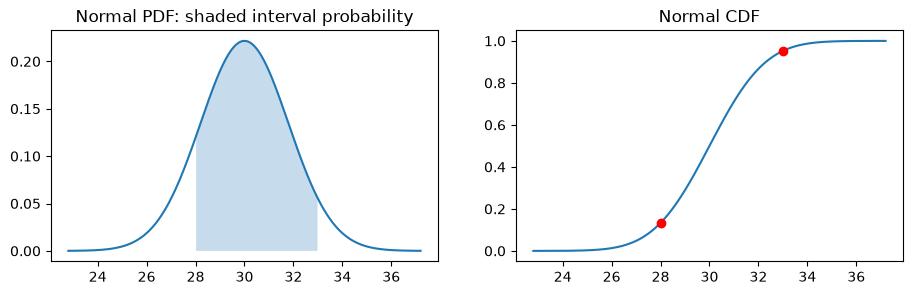

In [9]:
# OPTIONAL PLOT — run the preceding probability cell first.
x = np.linspace(np.array([mu - 4 * std, lower]).min(),
                np.array([mu + 4 * std, upper]).max(), 500)
pdf = norm.pdf(x, loc=mu, scale=std)
cdf = norm.cdf(x, loc=mu, scale=std)
inside = (x >= lower) & (x <= upper)
fig, axs = plt.subplots(1, 2, figsize=(11, 3))
axs[0].plot(x, pdf)
axs[0].fill_between(x[inside], pdf[inside], 0, alpha=0.25)
axs[0].set_title("Normal PDF: shaded interval probability")
axs[1].plot(x, cdf)
axs[1].plot([lower, upper], [F_lower, F_upper], "ro")
axs[1].set_title("Normal CDF")
plt.show()


<a id="q05"></a>
## 5. Question type: rank, determinant, and which inverse exists
**Source:** Tut3 Q10; Tut4 Q1–8 and `checkLR`; Tut6 Q7.

**Theory.** Rank counts independent columns/rows. For $X\in\mathbb R^{m\times d}$:

| Condition | Inverse and identity |
| :--- | :--- |
| Square and rank $d$ | $X^{-1}$; $X^{-1}X=XX^{-1}=I$ |
| Full column rank: rank $d$ | Left inverse $L=(X^TX)^{-1}X^T$; $LX=I_d$ |
| Full row rank: rank $m$ | Right inverse $R=X^T(XX^T)^{-1}$; $XR=I_m$ |
| Rank below both $m$ and $d$ | Neither left nor right inverse |

A determinant is defined only for square matrices. $X^TX$ is invertible iff $X$ has full column rank; $XX^T$ is invertible iff it has full row rank. A tiny numerical determinant or an apparently huge computed inverse does not establish invertibility; Tut4 explicitly demonstrates this pitfall.

**Your input:** replace `X`. The helper checks rank before inverting. Gram-matrix ranks may be more sensitive to rounding because forming them squares the condition number.


In [10]:
# EDIT INPUTS — try square, tall, wide, or rank-deficient matrices.
X = np.array([[1, 2, 3],
              [1, -2, 3]], dtype=float)

inverse = checkLR(X)
m, d = X.shape
rank = np.linalg.matrix_rank(X)
print("Full row rank?", rank == m)
print("Full column rank?", rank == d)
print("X.T @ X shape/rank:", (X.T @ X).shape, np.linalg.matrix_rank(X.T @ X))
print("X @ X.T shape/rank:", (X @ X.T).shape, np.linalg.matrix_rank(X @ X.T))


Shape: (2, 3)   Rank: 2
Right inverse exists (full row rank):
 [[ 0.05  0.05]
 [ 0.25 -0.25]
 [ 0.15  0.15]]
X @ right inverse (identity):
 [[1.00000000e+00 1.11022302e-16]
 [5.55111512e-17 1.00000000e+00]]
Full row rank? True
Full column rank? False
X.T @ X shape/rank: (3, 3) 2
X @ X.T shape/rank: (2, 2) 2


<a id="q06"></a>
## 6. Question type: classify a linear system, including singular cases
**Source:** Tut4 reference analysis.

**Theory.** For $Xw=y$, compare $r=\operatorname{rank}(X)$ with $r_a=\operatorname{rank}([X\mid y])$. An exact solution exists iff $r=r_a$. Nullity is $d-r$.

| Ranks / nullity | Meaning |
| :--- | :--- |
| $r=r_a$ and $d-r=0$ | Unique exact solution |
| $r=r_a$ and $d-r>0$ | Infinitely many exact solutions |
| $r\ne r_a$ and $d-r=0$ | No exact solution; unique least-squares minimizer |
| $r\ne r_a$ and $d-r>0$ | No exact solution; infinitely many least-squares minimizers |

$X^+y$ returns the minimum-norm least-squares solution; it is exact when the system is consistent. **Shape alone does not determine consistency or uniqueness.** A nearly zero residual indicates numerical agreement, subject to scale and rounding.

**Your input:** replace `X` and `y`; one target per row. For the singular example below, `y=[[0],[0]]` is consistent and `y=[[0],[1]]` is inconsistent.


In [11]:
# EDIT INPUTS
X = np.array([[1, 2],
              [3, 6]], dtype=float)
y = np.array([[0], [1]], dtype=float)

analysis, tutorial_method = analyze_linear_system(X, y)
pprint(analysis)
pprint(tutorial_method)
w = analysis["solution"]
print("X @ w:\n", X @ w)
print("Residual X @ w - y:\n", X @ w - y)


{'consistent': np.False_,
 'nullity': np.int64(1),
 'rank_X': np.int64(1),
 'rank_augmented': np.int64(2),
 'residual_norm': np.float64(0.31622776601683794),
 'solution': array([[0.06],
       [0.12]]),
 'solution_type': 'No exact solution; infinitely many least-squares solutions '
                  '(minimum-norm returned)'}
{'inverse_type_tut4': 'Rank deficient: Tut4 pseudoinverse fallback',
 'residual_norm_tut4': np.float64(0.31622776601683794),
 'solution_tut4': array([[0.06],
       [0.12]])}
X @ w:
 [[0.3]
 [0.9]]
Residual X @ w - y:
 [[ 0.3]
 [-0.1]]


<a id="q07"></a>
## 7. Question type: solve a square, invertible system exactly
**Source:** Tut4 Q1; Tut5 Q2 without bias.

**Theory.** If $m=d=\operatorname{rank}(X)$, $w=X^{-1}y$ is the unique exact solution. Check $Xw-y\approx0$. Never apply the square inverse to a singular or non-square matrix.

**Your input:** enter the coefficients in `X` and right-hand sides in `y`. These are the supplied equations; do not add an intercept column automatically. If a rank assertion fails, use Question 6.


In [12]:
# EDIT INPUTS
X = np.array([[1, 1],
              [3, 4]], dtype=float)
y = np.array([[0], [1]], dtype=float)

assert X.shape[0] == X.shape[1] == np.linalg.matrix_rank(X), "Use Q6: X is not square and full rank."
assert y.shape == (X.shape[0], 1)
X_inverse = np.linalg.inv(X)
w = X_inverse @ y
print("Inverse:\n", X_inverse)
print("w:\n", w)
print("Residual norm:", np.linalg.norm(X @ w - y))


Inverse:
 [[ 4. -1.]
 [-3.  1.]]
w:
 [[-1.]
 [ 1.]]
Residual norm: 2.220446049250313e-16


<a id="q08"></a>
## 8. Question type: tall system and least squares
**Source:** Tut4 Q3.

**Theory.** Minimize $\|Xw-y\|_2^2$. The normal equations are $X^TXw=X^Ty$. With full column rank, the unique minimizer is $w=(X^TX)^{-1}X^Ty$. The fitted target $\hat y=Xw$ is the projection onto the column space of $X$; its residual satisfies $X^T(Xw-y)\approx0$. A tall system can still have an exact solution if $y$ is in that column space.

**Your input:** replace `X`, `y`. Keep the target as a column. If columns are dependent, use Question 6 or `np.linalg.pinv(X) @ y` (from Tut4).


In [13]:
# EDIT INPUTS
X = np.array([[1, 2],
              [2, 4],
              [1, -1]], dtype=float)
y = np.array([[0], [0.1], [1]], dtype=float)

assert X.shape[0] >= X.shape[1] == np.linalg.matrix_rank(X), "Full column rank is required; use Q6 otherwise."
assert y.shape == (X.shape[0], 1)
left_inverse = np.linalg.inv(X.T @ X) @ X.T
w = left_inverse @ y
y_hat = X @ w
residual = y_hat - y
print("w:\n", w)
print("Fitted targets:\n", y_hat)
print("Residual:\n", residual)
print("SSE:", np.linalg.norm(residual) ** 2)
print("MSE:", (residual ** 2).mean())
print("Normal-equation check X.T @ residual:\n", X.T @ residual)


w:
 [[ 0.68]
 [-0.32]]
Fitted targets:
 [[0.04]
 [0.08]
 [1.  ]]
Residual:
 [[ 0.04]
 [-0.02]
 [ 0.  ]]
SSE: 0.002
MSE: 0.0006666666666666666
Normal-equation check X.T @ residual:
 [[-9.43689571e-16]
 [-1.88737914e-15]]


<a id="q09"></a>
## 9. Question type: wide system and minimum-norm exact solution
**Source:** Tut4 Q4 and Q6.

**Theory.** A wide, full-row-rank matrix has infinitely many exact solutions. Minimizing $\tfrac12\|w\|_2^2$ subject to $Xw=y$ selects
$$w_{\min}=X^T(XX^T)^{-1}y.$$
Here $XX^T$ is invertible, while $X^TX$ is singular. Full row rank guarantees a solution for every target $y$. The general solution adds a vector in the null space (Question 10).

**Your input:** replace `X`, `y`. Use the right inverse only when `rank(X)` equals its number of rows.


In [14]:
# EDIT INPUTS
X = np.array([[1, 0, 1, 0],
              [1, -1, 1, -1],
              [1, 1, 0, 0]], dtype=float)
y = np.array([[1], [0], [1]], dtype=float)

assert X.shape[1] > X.shape[0] == np.linalg.matrix_rank(X), "A wide, full-row-rank matrix is required."
assert y.shape == (X.shape[0], 1)
right_inverse = X.T @ np.linalg.inv(X @ X.T)
w = right_inverse @ y
print("Minimum-norm w:\n", w)
print("X @ w:\n", X @ w)
print("Residual norm:", np.linalg.norm(X @ w - y))
print("Weight norm:", np.linalg.norm(w))


Minimum-norm w:
 [[0.5]
 [0.5]
 [0.5]
 [0.5]]
X @ w:
 [[1.]
 [0.]
 [1.]]
Residual norm: 0.0
Weight norm: 1.0


<a id="q10"></a>
## 10. Question type: null space and all solutions
**Source:** Tut4 Q6 SVD; extension of its one null direction to all null directions using the same SVD operation.

**Theory.** If the columns of $N$ span $\operatorname{null}(X)$, then $XN=0$ and $w=w_0+Nc$ for arbitrary coefficients $c$. With $w_0=X^+y$, this is the family of all exact solutions if consistent, or all least-squares minimizers if inconsistent. SVD gives $X=U\Sigma V^T$; the last $d-r$ columns of $V$ form a null-space basis. The minimum-norm member uses $c=0$.

**Your input:** replace `X`, `y`. `c` needs one coefficient per null direction; change the multiplier below or replace it with `np.array([[c1], [c2], ...])`. This template uses the same absolute cutoff for rank and pseudoinverse.


In [15]:
# EDIT INPUTS
X = np.array([[1, 2, 1],
              [2, 4, -1]], dtype=float)
y = np.array([[0], [1]], dtype=float)
tol = 1e-10

U, S, Vt = np.linalg.svd(X, full_matrices=True)
rank = np.linalg.matrix_rank(X, tol=tol)
N = Vt[rank:, :].T
rcond = tol / S[0] if S[0] > 0 else tol
w0 = np.linalg.pinv(X, rcond=rcond) @ y
c = 2 * np.ones((N.shape[1], 1))  # EDIT: arbitrary null-space coefficients.
w_family = w0 + N @ c

print("Nullity:", N.shape[1])
print("Null-space basis N:\n", N)
print("Null-space check norm ||X @ N||:", np.linalg.norm(X @ N))
print("Minimum-norm member w0:\n", w0)
print("Chosen family member:\n", w_family)
print("Residual norms:", np.linalg.norm(X @ w0 - y), np.linalg.norm(X @ w_family - y))
print("Weight norms (minimum, chosen):", np.linalg.norm(w0), np.linalg.norm(w_family))


Nullity: 1
Null-space basis N:
 [[-8.94427191e-01]
 [ 4.47213595e-01]
 [-3.33066907e-16]]
Null-space check norm ||X @ N||: 4.710277376051325e-16
Minimum-norm member w0:
 [[ 0.06666667]
 [ 0.13333333]
 [-0.33333333]]
Chosen family member:
 [[-1.72218772]
 [ 1.02776052]
 [-0.33333333]]
Residual norms: 2.220446049250313e-16 1.066334393690002e-15
Weight norms (minimum, chosen): 0.3651483716701108 2.0330600909302543


<a id="q11"></a>
## 11. Question type: visualize equations in two unknowns
**Source:** Tut4 Q1–3.

**Theory.** Each equation $a_iw_1+b_iw_2=y_i$ is a line. Intersecting lines give exact solutions; parallel distinct lines do not. The least-squares point minimizes the sum of squared algebraic residuals (not necessarily the sum of squared geometric distances unless rows are normalized).

**Your input:** use exactly two columns in `X`, one right-hand side per row in `y`, and adjust the horizontal plot range. The code handles vertical lines without dividing by zero and marks the pseudoinverse solution.


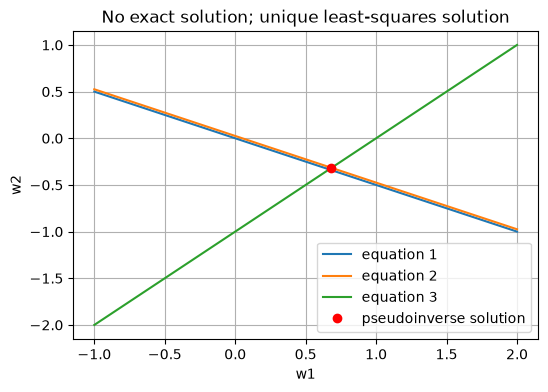

In [16]:
# EDIT INPUTS
X = np.array([[1, 2], [2, 4], [1, -1]], dtype=float)
y = np.array([[0], [0.1], [1]], dtype=float)
w1_min, w1_max = -1, 2
assert X.shape[1] == 2 and y.shape == (X.shape[0], 1)

analysis, _ = analyze_linear_system(X, y)
w = analysis["solution"]
horizontal = np.linspace(w1_min, w1_max, 200)
fig, ax = plt.subplots(figsize=(6, 4))
for i in range(X.shape[0]):
    a, b = X[i, 0], X[i, 1]
    if b != 0:
        ax.plot(horizontal, (y[i, 0] - a * horizontal) / b, label=f"equation {i + 1}")
    elif a != 0:
        ax.axvline(y[i, 0] / a, label=f"equation {i + 1}")
    else:
        print("Zero-coefficient equation", i + 1, ": 0 =", y[i, 0])
ax.plot(w[0, 0], w[1, 0], "ro", label="pseudoinverse solution")
ax.set_xlabel("w1")
ax.set_ylabel("w2")
ax.set_title(analysis["solution_type"])
ax.grid()
ax.legend()
plt.show()


<a id="q12"></a>
## 12. Question type: two planes and a line of solutions (optional)
**Source:** Tut4 Q6.

**Theory.** Two independent equations in three unknowns define intersecting planes. Their intersection is $w=w_{\min}+tn$, where $n$ is a null-space direction. The minimum-norm point is the point on that line closest to the origin.

**Your input:** replace `X` with a full-row-rank $2\times3$ matrix and `y` with two targets. This plotting form requires both coefficients of $w_3$ to be nonzero; otherwise rearrange variables or use Question 10 without a surface plot.


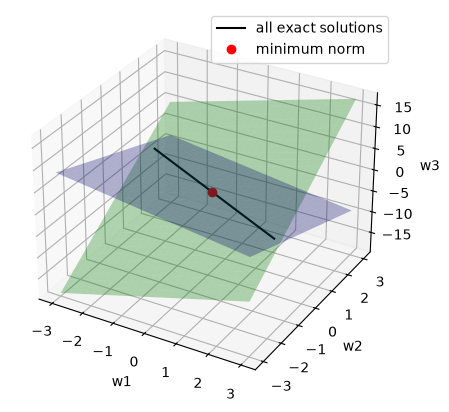

In [17]:
# EDIT INPUTS
X = np.array([[1, 2, 1], [2, 4, -1]], dtype=float)
y = np.array([[0], [1]], dtype=float)
plot_min, plot_max = -3, 3
assert X.shape == (2, 3) and np.linalg.matrix_rank(X) == 2
assert y.shape == (2, 1) and X[0, 2] != 0 and X[1, 2] != 0

w = X.T @ np.linalg.inv(X @ X.T) @ y
U, S, Vt = np.linalg.svd(X)
n = Vt[-1].reshape(3, 1)
n = n / np.linalg.norm(n)
t = np.linspace(plot_min, plot_max, 100)
W_line = w + n * t
grid = np.linspace(plot_min, plot_max, 30)
XX, YY = np.meshgrid(grid, grid)
Z1 = (y[0, 0] - X[0, 0] * XX - X[0, 1] * YY) / X[0, 2]
Z2 = (y[1, 0] - X[1, 0] * XX - X[1, 1] * YY) / X[1, 2]
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(XX, YY, Z1, color="b", alpha=0.3)
ax.plot_surface(XX, YY, Z2, color="g", alpha=0.3)
ax.plot(W_line[0], W_line[1], W_line[2], "k", label="all exact solutions")
ax.plot([w[0, 0]], [w[1, 0]], [w[2, 0]], "ro", label="minimum norm")
ax.set_xlabel("w1")
ax.set_ylabel("w2")
ax.set_zlabel("w3")
ax.legend()
plt.show()


<a id="q13"></a>
## 13. Question type: linear regression with/without an intercept
**Source:** Tut5 Q1–3.

**Theory.** With an intercept, $\hat y=b+w_1x_1+\cdots+w_px_p$ and the design is $P=[\mathbf1\ X]$. Without one, $P=X$ and the model passes through the origin. Fit by least squares and predict with the **same columns in the same order**. With a bias column, `w[0]` is the intercept. Interpolation is within the training range; extrapolation outside it is often less reliable.

**Your input:** enter raw `X`, target column `y`, and raw `X_new`. The helper adds one bias column. If the exam already gives a design matrix, use it as `X` with `include_bias=False`. The optional plotting cell below is only for one feature and one output.


In [18]:
# EDIT INPUTS — raw features: no leading column of ones.
X = np.array([[-10], [-8], [-3], [-1], [2], [8]], dtype=float)
y = np.array([[5], [5], [4], [3], [2], [2]], dtype=float)
X_new = np.array([[9], [0]], dtype=float)

w_bias, mse_bias, _ = PolyReg(X, y, n=1, include_bias=True)
w_no_bias, mse_no_bias, _ = PolyReg(X, y, n=1, include_bias=False)
# Explicit construction from Tut5, so the matrix multiplication is visible.
P_new = np.concatenate((np.ones((X_new.shape[0], 1)), X_new), axis=1)
print("With bias: w =\n", w_bias, "\nTraining MSE:", mse_bias)
print("Without bias: w =\n", w_no_bias, "\nTraining MSE:", mse_no_bias)
print("Predictions with bias:\n", P_new @ w_bias)
print("Predictions without bias:\n", X_new @ w_no_bias)


Design shape: (6, 2)  Rank: 2  Method: Left inverse / least squares
Design shape: (6, 1)  Rank: 1  Method: Left inverse / least squares
With bias: w =
 [[ 3.10550459]
 [-0.19724771]] 
Training MSE: 0.1697247706422019
Without bias: w =
 [[-0.35123967]] 
Training MSE: 8.857438016528926
Predictions with bias:
 [[1.33027523]
 [3.10550459]]
Predictions without bias:
 [[-3.16115702]
 [ 0.        ]]


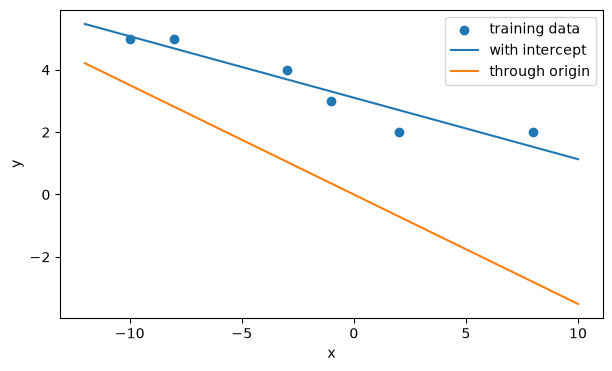

In [19]:
# OPTIONAL PLOT — run the preceding fit cell first; one input and output only.
assert X.shape[1] == 1 and y.shape[1] == 1
xx = np.linspace(X.min() - 2, X.max() + 2, 200).reshape(-1, 1)
P_xx = np.concatenate((np.ones((len(xx), 1)), xx), axis=1)
plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], y[:, 0], label="training data")
plt.plot(xx[:, 0], (P_xx @ w_bias)[:, 0], label="with intercept")
plt.plot(xx[:, 0], (xx @ w_no_bias)[:, 0], label="through origin")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


<a id="q14"></a>
## 14. Question type: multiple features and multiple outputs
**Source:** Tut5 Q2 and Q9.

**Theory.** Each row of $X$ is a sample; each column of $Y$ is an output. A single matrix $W\in\mathbb R^{d\times k}$ fits all output columns: $W=(P^TP)^{-1}P^TY$ for full column rank. Predictions are $\hat Y_{new}=P_{new}W$. Multioutput regression is different from classification: these outputs are numerical targets, not class scores.

**Your input:** enter raw features and a target matrix with the same number of rows. One new row may contain several features. Use `include_bias=False` if a supplied `X` already contains the intercept, as Tut5 Q9 does. Here its leading ones have been removed before input to the helper.


In [20]:
# EDIT INPUTS — one sample per row, three raw features, two outputs.
X = np.array([[3, -1, 0], [5, 1, 2], [9, -1, 3],
              [-6, 7, 2], [3, -2, 0]], dtype=float)
Y = np.array([[1, -1], [-1, 0], [1, 2], [0, 3], [1, -2]], dtype=float)
X_new = np.array([[8, 0, 2]], dtype=float)

W, train_mse, _ = PolyReg(X, Y, n=1)
P_new = np.concatenate((np.ones((len(X_new), 1)), X_new), axis=1)
print("W (rows=coefficients, columns=outputs):\n", W)
print("New predictions:\n", P_new @ W)
print("Training MSE averaged over samples and outputs:", train_mse)


Design shape: (5, 4)  Rank: 4  Method: Left inverse / least squares
W (rows=coefficients, columns=outputs):
 [[ 1.14668974 -0.95997404]
 [-0.630463   -0.33427088]
 [-1.10601471 -0.24426655]
 [ 1.3595846   1.77953267]]
New predictions:
 [[-1.17784509 -0.07507572]]
Training MSE averaged over samples and outputs: 0.2541107745564691


<a id="q15"></a>
## 15. Question type: construct a polynomial design matrix
**Source:** Tut6 Q2–3.

**Theory.** Polynomial regression is linear in its coefficients. For one raw feature and degree 3, a row becomes $[1,x,x^2,x^3]$. With two raw features and degree 2 the columns are $[1,x_0,x_1,x_0^2,x_0x_1,x_1^2]$. `PolynomialFeatures` includes interactions and all degrees up to `degree`; use `get_feature_names_out()` to inspect the actual order. With $p$ raw features and a bias, the number of columns is $\binom{p+n}{n}$.

**Your input:** edit `X`, `X_new`, and `degree`. Pass raw features; **do not manually add ones first** unless the problem explicitly treats a constant as a raw feature, as in Tut6 Q3. Fit the feature mapper on training data, then call `transform` on new data with the same feature count.


In [21]:
# EDIT INPUTS
X = np.array([[2, 3], [4, 5]], dtype=float)
X_new = np.array([[6, 7]], dtype=float)
degree = 2

poly = PolynomialFeatures(degree)
P = poly.fit_transform(X)
P_new = poly.transform(X_new)
print("Column order:", poly.get_feature_names_out())
print("Training design matrix:\n", P)
print("New design matrix:\n", P_new)
print("Shape / rank:", P.shape, np.linalg.matrix_rank(P))


Column order: ['1' 'x0' 'x1' 'x0^2' 'x0 x1' 'x1^2']
Training design matrix:
 [[ 1.  2.  3.  4.  6.  9.]
 [ 1.  4.  5. 16. 20. 25.]]
New design matrix:
 [[ 1.  6.  7. 36. 42. 49.]]
Shape / rank: (2, 6) 2


<a id="q16"></a>
## 16. Question type: fit polynomial regression and predict
**Source:** Tut5 `PolyReg`; Tut6 Q2.

**Theory.** Build $P=\phi(X)$, fit $w$ using the valid inverse for its shape **and rank**, then predict $\hat y_{new}=\phi(X_{new})w$. For degree 3 and one input, $\hat y=w_0+w_1x+w_2x^2+w_3x^3$. Increasing degree can fit training data more closely but does not guarantee better test performance.

**Your input:** edit raw `X`, column `y`, raw `X_new`, `degree`, and `lmd` (`0` ordinary; positive for ridge). The feature mapper used for predictions below has the same settings and training inputs as the helper. Do not use a different degree or add an extra bias column at prediction time.


In [22]:
# EDIT INPUTS
X = np.array([[-10], [-8], [-3], [-1], [2], [8]], dtype=float)
y = np.array([[5], [5], [4], [3], [2], [2]], dtype=float)
X_new = np.array([[9]], dtype=float)
degree = 3
lmd = 0.0

w, train_mse, _ = PolyReg(X, y, n=degree, lmd=lmd)
poly = PolynomialFeatures(degree)
P = poly.fit_transform(X)
P_new = poly.transform(X_new)
y_new = P_new @ w
print("Coefficient order:", poly.get_feature_names_out())
print("w:\n", w)
print("Training MSE:", train_mse)
print("New prediction:\n", y_new)


Design shape: (6, 4)  Rank: 4  Method: Left inverse / least squares
Coefficient order: ['1' 'x0' 'x0^2' 'x0^3']
w:
 [[ 2.68935636]
 [-0.37722517]
 [ 0.01343815]
 [ 0.00285772]]
Training MSE: 0.006324907037829737
New prediction:
 [[2.46609771]]


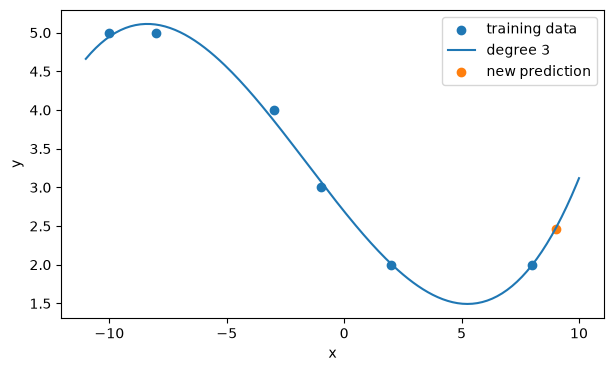

In [23]:
# OPTIONAL PLOT — one feature and output; run the preceding fit cell first.
assert X.shape[1] == 1 and y.shape[1] == 1
plot_inputs = np.concatenate((X, X_new), axis=0)
xx = np.linspace(plot_inputs.min() - 1, plot_inputs.max() + 1, 200).reshape(-1, 1)
yy = poly.transform(xx) @ w
plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], y[:, 0], label="training data")
plt.plot(xx[:, 0], yy[:, 0], label=f"degree {degree}")
plt.scatter(X_new[:, 0], y_new[:, 0], label="new prediction")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


<a id="q17"></a>
## 17. Question type: polynomial features produce a wide design
**Source:** Tut6 Q3.

**Theory.** Feature expansion can give more coefficients than samples. If $P$ has full row rank, $w=P^T(PP^T)^{-1}y$ is the minimum-norm interpolating solution. $P^TP$ is singular for a wide matrix, so its ordinary inverse is invalid. Width alone is insufficient: duplicate/dependent sample rows can also make $PP^T$ singular.

**Your input:** edit `X`, `y`, `degree`. To match Tut6 Q3 exactly, the sample contains a constant raw feature; its polynomial expansion has redundant columns. The helper tests rank and switches to Tut4's pseudoinverse if needed.


In [24]:
# EDIT INPUTS — original Tut6 Q3 inputs.
X = np.array([[1, 0, 1], [1, -1, 1]], dtype=float)
y = np.array([[0], [1]], dtype=float)
degree = 3

poly = PolynomialFeatures(degree)
P = poly.fit_transform(X)
print("P shape:", P.shape, " Rank:", np.linalg.matrix_rank(P))
if P.shape[1] > P.shape[0] == np.linalg.matrix_rank(P):
    w = P.T @ np.linalg.inv(P @ P.T) @ y
    print("Dual/right-inverse weights:\n", w)
else:
    w = np.linalg.pinv(P) @ y
    print("Full-row-rank condition failed: Tut4 pseudoinverse used.\n", w)
print("Training predictions:\n", P @ w)
print("Training residual norm:", np.linalg.norm(P @ w - y))


P shape: (2, 20)  Rank: 2
Dual/right-inverse weights:
 [[ 0. ]
 [ 0. ]
 [-0.1]
 [ 0. ]
 [ 0. ]
 [-0.1]
 [ 0. ]
 [ 0.1]
 [-0.1]
 [ 0. ]
 [ 0. ]
 [-0.1]
 [ 0. ]
 [ 0.1]
 [-0.1]
 [ 0. ]
 [-0.1]
 [ 0.1]
 [-0.1]
 [ 0. ]]
Training predictions:
 [[0.]
 [1.]]
Training residual norm: 0.0


<a id="q18"></a>
## 18. Question type: ridge regression in primal and dual form
**Source:** Tut5 `PolyReg`; Tut6 Q3.

**Theory.** Minimize $\|Pw-y\|_2^2+\lambda\|w\|_2^2$ with $\lambda>0$:
$$w_{primal}=(P^TP+\lambda I_d)^{-1}P^Ty,\qquad
w_{dual}=P^T(PP^T+\lambda I_m)^{-1}y.$$
These give the same coefficients mathematically; floating-point results can differ slightly. Use primal when $d\le m$ and dual when $m<d$ to invert the smaller matrix. Positive $\lambda$ makes the ridge matrices invertible even with rank deficiency. Ridge need not interpolate the training targets.

**Your input:** edit raw `X`, targets `y`, `degree`, and `lmd`. The identity size belongs to the matrix being inverted. **The tutorial convention penalizes every coefficient, including the intercept.** These formulas use an unnormalized sum of squared errors; if a question defines the loss differently, use its specified scaling of $\lambda$.


In [25]:
# EDIT INPUTS
X = np.array([[1, 0, 1], [1, -1, 1]], dtype=float)
y = np.array([[0], [1]], dtype=float)
degree = 3
lmd = 1e-4
assert lmd > 0, "This comparison needs positive ridge regularization."

poly = PolynomialFeatures(degree)
P = poly.fit_transform(X)
m, d = P.shape
w_primal = np.linalg.inv(P.T @ P + lmd * np.identity(d)) @ P.T @ y
w_dual = P.T @ np.linalg.inv(P @ P.T + lmd * np.identity(m)) @ y
print("Primal matrix size:", (d, d), " Dual matrix size:", (m, m))
print("Primal weights:\n", w_primal)
print("Dual weights:\n", w_dual)
print("Coefficient difference norm:", np.linalg.norm(w_primal - w_dual))
print("Training predictions:\n", P @ w_dual)
print("Training MSE:", mean_squared_error(y, P @ w_dual))
print("Ridge objective:", np.linalg.norm(P @ w_dual - y) ** 2 + lmd * np.linalg.norm(w_dual) ** 2)


Primal matrix size: (20, 20)  Dual matrix size: (2, 2)
Primal weights:
 [[ 9.99973963e-07]
 [ 9.99967597e-07]
 [-9.99980000e-02]
 [ 9.99974532e-07]
 [ 9.99971803e-07]
 [-9.99980000e-02]
 [ 9.99968279e-07]
 [ 9.99980001e-02]
 [-9.99980001e-02]
 [ 9.99970325e-07]
 [ 9.99969984e-07]
 [-9.99980000e-02]
 [ 9.99967597e-07]
 [ 9.99980001e-02]
 [-9.99980001e-02]
 [ 9.99971007e-07]
 [-9.99980001e-02]
 [ 9.99980000e-02]
 [-9.99980000e-02]
 [ 9.99969416e-07]]
Dual weights:
 [[ 9.99970001e-07]
 [ 9.99970001e-07]
 [-9.99980000e-02]
 [ 9.99970001e-07]
 [ 9.99970001e-07]
 [-9.99980000e-02]
 [ 9.99970001e-07]
 [ 9.99980000e-02]
 [-9.99980000e-02]
 [ 9.99970001e-07]
 [ 9.99970001e-07]
 [-9.99980000e-02]
 [ 9.99970001e-07]
 [ 9.99980000e-02]
 [-9.99980000e-02]
 [ 9.99970001e-07]
 [-9.99980000e-02]
 [ 9.99980000e-02]
 [-9.99980000e-02]
 [ 9.99970001e-07]]
Coefficient difference norm: 8.734534699380615e-12
Training predictions:
 [[9.99970001e-06]
 [9.99990000e-01]]
Training MSE: 9.999500019440148e-11
Ridg

<a id="q19"></a>
## 19. Question type: split data, fit, and compute regression error
**Source:** Tut5 Q6 and `PolyReg`.

**Theory.** Learn weights using training samples only; predict held-out targets without refitting. For one output, $\mathrm{MSE}=\frac1N\sum_i(\hat y_i-y_i)^2$. SSE omits the division by $N$. A small training error alone does not establish generalization. `random_state` makes the split reproducible; `test_size` is a fraction (or an integer sample count). If the question specifies the split, use it exactly.

**Your input:** replace `X_all`, `y_all`, `test_fraction`, `seed`, `degree`, `lmd`. If train/test matrices are already provided, replace the split line with their assignments. Keep targets and predictions the same shape before manual MSE.


In [26]:
# EDIT INPUTS
X_all = np.array([[36], [28], [35], [39], [30], [30],
                  [31], [38], [36], [38], [29], [26]], dtype=float)
y_all = np.array([[31], [29], [34], [35], [29], [30],
                  [30], [38], [34], [33], [29], [26]], dtype=float)
test_fraction = 0.25
seed = 42
degree = 1
lmd = 0.0

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=test_fraction, random_state=seed)
w, mse_train, mse_test = PolyReg(X_train, y_train, X_test, y_test, n=degree, lmd=lmd)
poly = PolynomialFeatures(degree)
P_train = poly.fit_transform(X_train)
P_test = poly.transform(X_test)
y_pred = P_test @ w
print("Test inputs:\n", X_test)
print("Test targets:\n", y_test)
print("Test predictions:\n", y_pred)
print("Training MSE:", mse_train, " Test MSE:", mse_test)
print("Manual test MSE:", ((y_pred - y_test) ** 2).mean())


Design shape: (9, 2)  Rank: 2  Method: Left inverse / least squares
Test inputs:
 [[29.]
 [38.]
 [36.]]
Test targets:
 [[29.]
 [33.]
 [31.]]
Test predictions:
 [[28.86261559]
 [35.96036988]
 [34.38309115]]
Training MSE: 1.0415382357258198  Test MSE: 6.742656677992254
Manual test MSE: 6.742656677992254


<a id="q20"></a>
## 20. Question type: binary classification by a regression score
**Source:** Tut6 Q4.

**Theory.** Encode two classes as $-1,+1$, fit a scalar regression score $s(x)=\phi(x)w$, and predict $\operatorname{sign}(s(x))$. Zero is the decision threshold. The score is not a class probability. `np.sign(0)` is `0`, so an exact zero needs a tie rule specified by the question. For degree 1 with bias, the boundary is $w_0+w_1x_1+\cdots=0$.

**Your input:** enter raw `X`, labels `y` using only `-1`/`+1`, and raw `X_new`. Use degree 1 and `lmd=0` to reproduce the tutorial. `y_new_true` is optional; set it to `None` if unknown.


In [27]:
# EDIT INPUTS — raw features; the helper adds the tutorial's bias column.
X = np.array([[-1], [0], [0.5], [0.3], [0.8]], dtype=float)
y = np.array([[1], [1], [-1], [1], [-1]], dtype=float)
X_new = np.array([[-0.1], [0.4]], dtype=float)
y_new_true = None  # Or np.array([1, -1]) if test labels are supplied.
degree = 1
lmd = 0.0
assert set(y.ravel()) <= {-1, 1}, "Binary sign workflow requires labels -1/+1."

w, _, _ = PolyReg(X, y, n=degree, lmd=lmd)
poly = PolynomialFeatures(degree)
P = poly.fit_transform(X)
scores = poly.transform(X_new) @ w
labels = np.sign(scores).ravel()
print("w:\n", w)
print("Scores:\n", scores)
print("Predicted classes:", labels)
if 0 in labels:
    print("A score is exactly zero: apply the question's specified tie rule.")
if y_new_true is not None:
    print("Test accuracy:", accuracy_score(np.array(y_new_true).ravel(), labels))


Design shape: (5, 2)  Rank: 2  Method: Left inverse / least squares
w:
 [[ 0.33333333]
 [-1.11111111]]
Scores:
 [[ 0.44444444]
 [-0.11111111]]
Predicted classes: [ 1. -1.]


<a id="q21"></a>
## 21. Question type: one-hot multiclass linear classification
**Source:** Tut6 Q5.

**Theory.** Convert one class label into a row of a one-hot target matrix $Y\in\mathbb R^{m\times k}$. Fit $W$ to those columns. A test sample gets scores $\phi(x)W$; choose the column with the largest score, then decode that column to its class label. Negative scores and scores whose sum is not one are possible. Accuracy is the fraction of correctly predicted labels.

**Your input:** enter raw `X`, one label per row in `y`, and raw `X_new`. This cell shows encoding, fitting, and decoding explicitly. Change labels freely, including to nonconsecutive numbers or strings; `categories_` supplies the correct output mapping. `y_new_true=None` skips test accuracy.


In [28]:
# EDIT INPUTS
X = np.array([[-1], [0], [0.5], [0.3], [0.8]], dtype=float)
y = np.array([1, 1, 2, 3, 2])
X_new = np.array([[-0.1], [0.4]], dtype=float)
y_new_true = None

ohe = OneHotEncoder(sparse_output=False)
Y = ohe.fit_transform(y.reshape(-1, 1))
classes = ohe.categories_[0]  # Column order; works for arbitrary label values.
W, _, _ = PolyReg(X, Y, n=1)
poly = PolynomialFeatures(1)
P = poly.fit_transform(X)
scores = poly.transform(X_new) @ W
labels = classes[np.argmax(scores, axis=1)]
train_labels = classes[np.argmax(P @ W, axis=1)]
print("One-hot column labels:", classes)
print("One-hot training targets:\n", Y)
print("W:\n", W)
print("Test scores (one column per class):\n", scores)
print("Predicted labels:", labels)
print("Training accuracy:", accuracy_score(y, train_labels))
if y_new_true is not None:
    print("Test accuracy:", accuracy_score(np.array(y_new_true).ravel(), labels))


Design shape: (5, 2)  Rank: 2  Method: Left inverse / least squares
One-hot column labels: [1 2 3]
One-hot training targets:
 [[1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]
W:
 [[ 0.47798742  0.33333333  0.18867925]
 [-0.64989518  0.55555556  0.09433962]]
Test scores (one column per class):
 [[0.54297694 0.27777778 0.17924528]
 [0.21802935 0.55555556 0.22641509]]
Predicted labels: [1 2]
Training accuracy: 0.8


<a id="q22"></a>
## 22. Question type: polynomial or ridge multiclass classification
**Source:** Tut6 Q5 and `PolyCls`.

**Theory.** Use polynomial features $P=\phi_n(X)$ and one-hot targets $Y$. The same least-squares/minimum-norm/ridge formulas apply with $Y$ in place of a target column. Decode the largest output score. The degree-5 tutorial example has 5 samples and 6 polynomial columns, so a full-row-rank design uses the dual/right inverse. A positive `lmd` changes this to ridge.

**Your input:** edit raw matrices, class labels, `degree`, and `lmd`. `PolyCls` reports training accuracy and test accuracy if supplied. The second part shows how to obtain class predictions from its returned weights using the same polynomial settings and class ordering.


In [29]:
# EDIT INPUTS
X = np.array([[-1], [0], [0.5], [0.3], [0.8]], dtype=float)
y = np.array([1, 1, 2, 3, 2])
X_new = np.array([[-0.1], [0.4]], dtype=float)
y_new_true = None
degree = 5
lmd = 0.0  # Change to a positive value if ridge is requested.

W, train_accuracy, test_accuracy = PolyCls(
    X, y, X_new, y_new_true, n=degree, lmd=lmd)
poly = PolynomialFeatures(degree)
P = poly.fit_transform(X)
ohe = OneHotEncoder(sparse_output=False)
Y = ohe.fit_transform(y.reshape(-1, 1))
scores = poly.transform(X_new) @ W
labels = ohe.categories_[0][np.argmax(scores, axis=1)]
print("Feature order:", poly.get_feature_names_out())
print("W:\n", W)
print("Test scores:\n", scores)
print("Predicted labels:", labels)
print("Training accuracy:", train_accuracy, " Test accuracy:", test_accuracy)


Design shape: (5, 6)  Rank: 5  Method: Right inverse / minimum norm
Feature order: ['1' 'x0' 'x0^2' 'x0^3' 'x0^4' 'x0^5']
W:
 [[ 1.00000000e+00  1.77635684e-13 -3.41060513e-13]
 [-5.30313768e+00 -3.70234958e+00  9.00548727e+00]
 [ 5.21976232e+00  1.08728407e+01 -1.60926030e+01]
 [ 6.66624941e+00  9.46978846e+00 -1.61360379e+01]
 [-6.47651463e+00 -1.29098961e+01  1.93864107e+01]
 [-2.61986403e+00 -7.80449422e+00  1.04243583e+01]]
Test scores:
 [[ 1.57522369  0.46828063 -1.04350432]
 [-0.05207932  0.45436978  0.59770954]]
Predicted labels: [1 3]
Training accuracy: 1.0  Test accuracy: None


<a id="q23"></a>
## 23. Question type: classification train/test split and accuracy comparison
**Source:** Tut6 Q6.

**Theory.** Split the data before learning weights. Fit polynomial mapping and label encoding on training data, use those mappings for testing, and compare predicted **labels** to the test labels. Changing the polynomial degree changes feature count, rank, and possibly the applicable inverse. Test labels must not influence weight fitting.

**Your input:** the default uses the tutorial's bundled Iris dataset, which needs no CSV/download. Replace `X_all`, `y_all` with your own arrays to use your exam data. Edit `test_fraction`, `seed`, `degrees`, and `lmd`. Match any specified split exactly. If model selection is requested, keep a final test set separate from the data used to choose the degree; repeated test comparison is only the tutorial's demonstration.


In [30]:
from sklearn.datasets import load_iris  # Already imported in Tut6 Q6.

# EDIT INPUTS — replace these assignments with your own arrays if given.
iris = load_iris()
X_all = iris["data"]
y_all = iris["target"]
test_fraction = 0.26
seed = 1
degrees = [1, 2]
lmd = 0.0

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=test_fraction, random_state=seed)
print("Training/test sample counts:", len(X_train), len(X_test))
for degree in degrees:
    W, train_accuracy, test_accuracy = PolyCls(
        X_train, y_train, X_test, y_test, n=degree, lmd=lmd)
    print(f"degree={degree}, lambda={lmd}: train accuracy={train_accuracy:.4f}, test accuracy={test_accuracy:.4f}")

# OPTIONAL: final model's actual test labels and scores.
poly = PolynomialFeatures(degrees[-1])
P_train = poly.fit_transform(X_train)
ohe = OneHotEncoder(sparse_output=False)
Y_train = ohe.fit_transform(np.array(y_train).reshape(-1, 1))
scores = poly.transform(X_test) @ W
labels = ohe.categories_[0][np.argmax(scores, axis=1)]
print("Predicted test labels:", labels)
print("True test labels:", y_test)
print("Manual accuracy:", (labels == np.array(y_test).ravel()).mean())


Training/test sample counts: 111 39
Design shape: (111, 5)  Rank: 5  Method: Left inverse / least squares
degree=1, lambda=0.0: train accuracy=0.8378, test accuracy=0.7692
Design shape: (111, 15)  Rank: 15  Method: Left inverse / least squares
degree=2, lambda=0.0: train accuracy=0.9910, test accuracy=1.0000
Predicted test labels: [0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 1 0 2 1 0 0 1 2 1 2 1 2 2 0 1
 0 1]
True test labels: [0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 1 0 2 1 0 0 1 2 1 2 1 2 2 0 1
 0 1]
Manual accuracy: 1.0


<a id="q24"></a>
## 24. Question type: load tabular data from your own CSV (optional)
**Source:** Tut5 Q5–6 (`pandas.read_csv`).

**Theory.** Select feature columns and a target column, convert to arrays, then use the same regression workflow. The CSV path is relative to the notebook folder unless an absolute path is supplied. The tutorials' machine-specific paths are examples and are not portable.

**Your input:** first set `run_csv=True`, then edit `csv_path`, `separator`, `feature_columns`, and `target_column` to match your file. Features/targets for this regression example must be numeric. A semicolon separator is needed for the wine CSV shown in Tut5. This cell is disabled by default so **Run All does not require external files**. For classification, replace `PolyReg` with `PolyCls` and interpret its outputs as accuracies.


In [31]:
# EDIT INPUTS — keep disabled unless your file is available.
run_csv = False
csv_path = "your_data.csv"
separator = ","
feature_columns = ["feature_1", "feature_2"]
target_column = "target"

if run_csv:
    import pandas as pd  # Already used in Tut5 Q4–6; only needed for CSV/duplicates.
    df = pd.read_csv(csv_path, sep=separator)
    print(df.describe())
    X_all = np.array(df[feature_columns], dtype=float)
    y_all = np.array(df[target_column], dtype=float).reshape(-1, 1)
    X_train, X_test, y_train, y_test = train_test_split(
        X_all, y_all, test_size=0.25, random_state=42)
    w, train_mse, test_mse = PolyReg(X_train, y_train, X_test, y_test)
    print("w:\n", w)
    print("Training MSE:", train_mse, " Test MSE:", test_mse)
else:
    print("CSV workflow skipped. Set run_csv=True and enter your file/column names to use it.")


CSV workflow skipped. Set run_csv=True and enter your file/column names to use it.


<a id="q25"></a>
## 25. Question type: effect of duplicate observations (optional)
**Source:** Tut5 Q4, explicitly marked out of scope there.

**Theory.** Repeating an identical $(x,y)$ pair adds its squared error repeatedly to the least-squares objective, giving that observation extra influence. Removing duplicates changes the objective and can change coefficients. Equal feature values with **different** targets are not identical observations and are not removed by this code.

**Your input:** this tutorial helper accepts one raw feature column and one target column. Replace `X`, `y`, and `X_new`. Only remove duplicates when the problem asks for it; repeated measurements can be intentional.


In [32]:
import pandas as pd  # Already used by the original Tut5 helper.

# Adapted from Tut5 purge_duplicate; still restricted to one feature/output.
def purge_duplicate(X, y):
    assert X.shape == y.shape and X.shape[1] == 1
    Xy = np.concatenate((X, y), axis=1)
    df = pd.DataFrame(Xy, columns=["X", "y"])
    df_new = df.drop_duplicates()
    X_new = np.array(df_new["X"]).reshape(-1, 1)
    y_new = np.array(df_new["y"]).reshape(-1, 1)
    return X_new, y_new

# EDIT INPUTS
X = np.array([[36], [26], [35], [39], [26], [30],
              [31], [38], [36], [38], [26], [26]], dtype=float)
y = np.array([[31], [20], [34], [35], [20], [30],
              [30], [38], [34], [33], [20], [20]], dtype=float)
X_new = np.array([[30]], dtype=float)

X_clean, y_clean = purge_duplicate(X, y)
w_all, _, _ = PolyReg(X, y)
w_clean, _, _ = PolyReg(X_clean, y_clean)
P_new = np.concatenate((np.ones((len(X_new), 1)), X_new), axis=1)
print("Rows before/after:", len(X), len(X_clean))
print("Weights before/after:\n", w_all, "\n", w_clean)
print("Prediction before/after:\n", P_new @ w_all, "\n", P_new @ w_clean)


Design shape: (12, 2)  Rank: 2  Method: Left inverse / least squares
Design shape: (9, 2)  Rank: 2  Method: Left inverse / least squares
Rows before/after: 12 9
Weights before/after:
 [[-10.41257051]
 [  1.21434327]] 
 [[-3.55844156]
 [ 1.02597403]]
Prediction before/after:
 [[26.01772764]] 
 [[27.22077922]]


## Quick input/error checklist

| Symptom / question | Action |
| :--- | :--- |
| `NameError` for a helper or import | Run all four setup code cells after a kernel restart. |
| Matrix multiplication dimension mismatch | Check `X.shape`, `y.shape`; one sample/equation per row. |
| One new sample with multiple features | Use `np.array([[a, b, c]])`, shape `(1, 3)`. |
| Several samples with one feature | Use `np.array([[a], [b], [c]])`, shape `(3, 1)`. |
| Targets are `(m,)` but predictions are `(m,1)` | Reshape targets with `.reshape(-1,1)` before subtracting. |
| Singular matrix / suspiciously huge inverse | Check rank first; use Q6 or the helper's Tut4 `pinv` fallback. |
| Already supplied a design matrix with ones | Do not add another bias. Use direct formulas, or `n=1, include_bias=False`. |
| Polynomial prediction has wrong coefficient count | Reuse the training degree, bias setting, raw feature count, and column order. |
| Class labels are not `0,...,K-1` | Decode indices through `ohe.categories_[0]`; do not blindly add 1. |
| Normal question gives variance | Take its square root before using `scale`. |
| Very high polynomial degree / badly scaled inputs | Expect numerical sensitivity; inspect rank and residuals; the tutorial's pseudoinverse is available. |
| CSV file unavailable | Leave Q24 disabled; all other examples use arrays or bundled data. |

**Coverage note:** the tutorial's optional Iris decision-boundary grid is labelled “Not required” in Tut6 and is omitted here. Its training, prediction, degree comparison, and accuracy workflows are covered above. Intentional error demonstrations from the tutorials have been replaced by rank checks and explanations so the default notebook can run from top to bottom.
